<a href="https://colab.research.google.com/github/Adekunle-joshua/Adekunle-joshua/blob/main/03_computer_vision_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# import PyTorch
import torch
from torch import nn

# import TorchVision
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor
# import matplotlib for visiualization
import matplotlib.pyplot as plt

In [ ]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
    target_transform=None,
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
    target_transform=None,
)

In [ ]:
len(train_data), len(test_data)

(60000, 10000)

In [ ]:
image, label = train_data[0]
image, label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [ ]:
image.size()

torch.Size([1, 28, 28])

In [ ]:
class_names =train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [ ]:
class_to_idx = train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

Text(0.5, 1.0, 'Ankle boot')

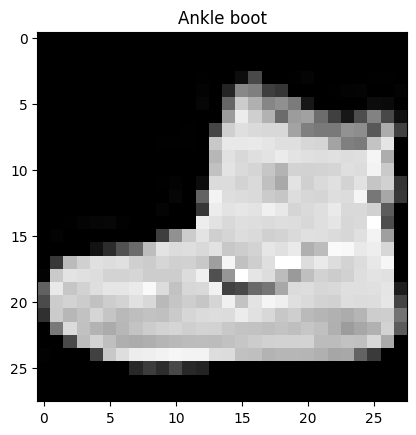

In [ ]:
# visualizing our data
plt.imshow(image.squeeze(), cmap="gray")
plt.title(class_names[label])


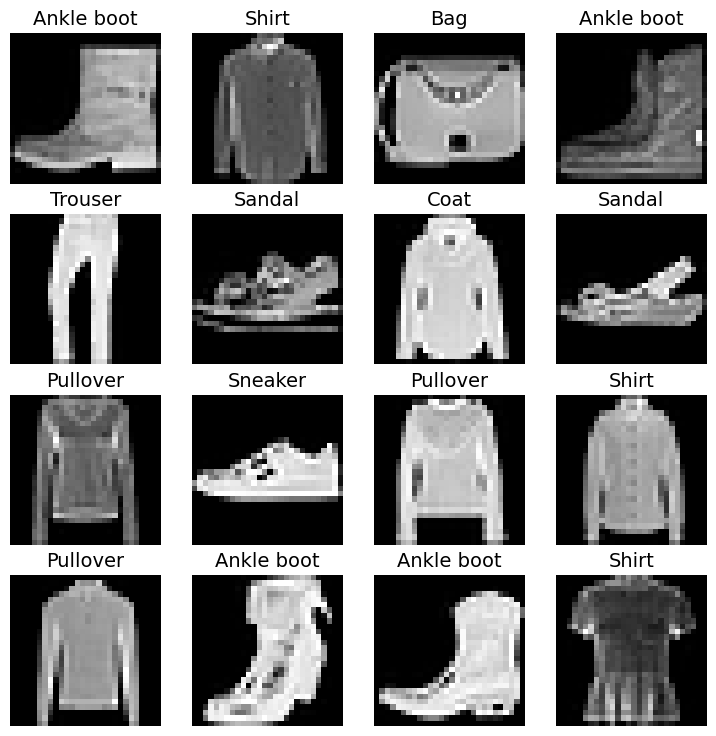

In [ ]:
from numpy._core.fromnumeric import size
torch.manual_seed(42)
fig = plt.figure(figsize=(9, 9))
rows, cols = 4, 4
for i in range(1, rows * cols + 1):
  random_idx = torch.randint(0, len(train_data), size=[1]).item()
  img, label = train_data[random_idx]
  fig.add_subplot(rows,cols,i)
  plt.imshow(img.squeeze(), cmap="gray")
  plt.title(class_names[label], fontsize=14)
  plt.axis(False)

In [ ]:
from torch.utils.data import DataLoader

In [ ]:
BATCH_SIZE = 32
train_dataloader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle= False)
train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x78df4b301940>,
 <torch.utils.data.dataloader.DataLoader at 0x78df4ae1fc50>)

In [ ]:
# chcecking the number of batches we have. PS we have split our training data into a batch of 32 samples
len(train_dataloader), len(test_dataloader)

(1875, 313)

In [ ]:
train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image SIze: torch.Size([1, 28, 28])


21

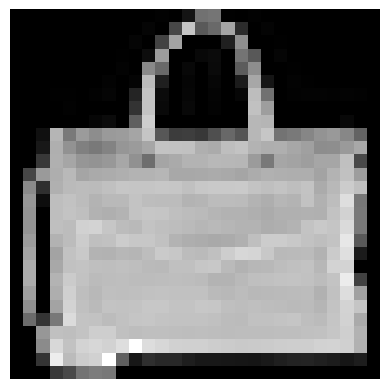

In [ ]:
# torch.manual_seed(42)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()
img, label = train_features_batch[random_idx], train_labels_batch[random_idx]
plt.imshow(img.squeeze(), cmap="gray")
plt.axis(False)
print(f"Image SIze: {img.shape}")
random_idx


We usually start trainin our model by first introducing a baseline model and then we improve the model through experimentation to avoid overfitting

In [ ]:
# create a flatten layer
flatten_model = nn.Flatten()

# get a single sample
X = train_features_batch[0]

# flaten the sample - by collapsing the 3 dimension data into a 2D and we can reduce .squeeze() to remove the extra dimension

output = flatten_model(X).squeeze()

output.shape,  X.shape

(torch.Size([784]), torch.Size([1, 28, 28]))

In [ ]:
class FashionMNISTModelV01(nn.Module):
  def __init__(self, input_shape, output_shape, hidden_units):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape, out_features=hidden_units),
        nn.Linear(in_features=hidden_units, out_features=output_shape)
    )

  def forward(self,x):
    return self.layer_stack(x)


In [ ]:
torch.manual_seed(42)
model = FashionMNISTModelV01(
    input_shape=28*28,
    output_shape=len(class_names),
    hidden_units=10
)
model

FashionMNISTModelV01(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [ ]:
def accuracy_fn(y_true, y_pred):
  correct = torch.eq(y_true, y_pred).sum().item()
  return correct / len(y_pred) * 100


In [ ]:
import requests
from pathlib import Path

In [ ]:
if Path("help_function.py").is_file():
  print("File already exists")
else:
  print("Downloading help_function.py")
  request = requests.get("https://raw.githubusercontent.com/Adekunle-joshua/pytorch-deep-learning/refs/heads/main/helper_functions.py")
  with open("helper_function.py", "wb") as f:
    f.write(request.content)

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.1)

In [ ]:
from timeit import default_timer as timer

In [ ]:
def print_train_time(start: float, end: float, device: torch.device = None):
  total_time = end - start
  print(f"Train time on {device} took {total_time:.3f} seconds")
  return total_time

In [ ]:

# tqdm is used for visual progress bar
from tqdm.auto import tqdm

# set random seed
torch.manual_seed(42)

# set time
train_time_start_cpu = timer()

# set number of epochs
epochs = 5

for epoch in tqdm(range(epochs)):
  print(f"Epoch:  {epoch}\n....")

  # training
  train_loss = 0
  for batch, (X, y) in enumerate(train_dataloader):
    model.train()
    y_pred = model(X)
    loss = loss_fn(y_pred, y)
    train_loss += loss.item()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if batch % 400 == 0:
      print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples")
  train_loss /= len(train_dataloader)

  test_loss, test_acc = 0,0
  model.eval()
  with torch.inference_mode():
    for X_test, y_test in test_dataloader:
      test_pred = model(X_test)
      test_loss += loss_fn(test_pred, y_test)
      test_acc += accuracy_fn(y_true=y_test, y_pred=test_pred.argmax(dim=1))
    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)

  print(f"Train loss: {train_loss:.5f} | Test Loss: {test_loss:.5f} | Test Acc: {test_acc:.2f}%")

train_time_end_on_cpu = timer()
total_train_time_model = print_train_time(start=train_time_start_cpu,
                                          end=train_time_end_on_cpu,
                                          device=str(next(model.parameters()).device))





  0%|          | 0/5 [00:00<?, ?it/s]

Epoch:  0
....
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples
Train loss: 0.59039 | Test Loss: 0.50954 | Test Acc: 82.04%
Epoch:  1
....
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples
Train loss: 0.47633 | Test Loss: 0.47989 | Test Acc: 83.20%
Epoch:  2
....
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples
Train loss: 0.45503 | Test Loss: 0.47664 | Test Acc: 83.43%
Epoch:  3
....
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples
Train loss: 0.44251 | Test Loss: 0.46306 | Test Acc: 83.75%
Epoch:  4
....
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400

In [ ]:
torch.manual_seed(42)
def eval_model(model: nn.Module,
               data_loader: DataLoader,
               loss_fn: nn.Module,
               accuracy_fn):
  """ Returns a dictionary containing the results of model predicting on data_loader"""
  loss, acc = 0, 0
  model.eval()
  with torch.inference_mode():
    for X, y in data_loader:
      X,y = X.to(device), y.to(device)
      y_pred = model(X)
      loss += loss_fn(y_pred, y)
      acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))
    loss /= len(data_loader)
    acc /= len(data_loader)
  return {"model_name": model.__class__.__name__,
          "model_loss": loss.item(),
          "model_acc": acc}



In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
model_01_results = eval_model(model=model,
                              data_loader=test_dataloader,
                              loss_fn=loss_fn,
                              accuracy_fn=accuracy_fn)
model_01_results

{'model_name': 'FashionMNISTModelV01',
 'model_loss': 0.46869373321533203,
 'model_acc': 83.2667731629393}

In [ ]:
class FashionMNISTModelV1(nn.Module):
  def __init__(self,input_shape, output_shape, hidden_units):
    super().__init__()
    self.layer_stack = nn.Sequential(
                                     nn.Flatten(),
                                     nn.Linear(in_features=input_shape, out_features=hidden_units),
                                     nn.ReLU(),
                                     nn.Linear(in_features=hidden_units, out_features=output_shape),
                                     nn.ReLU())
  def forward(self, x):
    return self.layer_stack(x)



In [ ]:
model_01 = FashionMNISTModelV1(input_shape=28*28, output_shape=len(class_names), hidden_units=10).to(device)
model_01

FashionMNISTModelV1(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): ReLU()
    (3): Linear(in_features=10, out_features=10, bias=True)
    (4): ReLU()
  )
)

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_01.parameters(), lr=0.1)
from helper_function import accuracy_fn

In [ ]:
def train_step(model, data_loader, loss_fn, optimizer, accuracy_fn, device = device):
  """Perfroms a training loop on a model"""
  train_loss, train_acc = 0,0
  model.train()
  for batch, (X,y) in enumerate(data_loader):
    X,y = X.to(device), y.to(device)
    y_pred = model(X)
    loss = loss_fn(y_pred, y)
    train_loss += loss.item()
    train_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f"train_loss", train_loss, "train_acc ", train_acc)
#


In [ ]:
def test_step(model,data_loader,loss_fn, optimizer, accuracy_fn, device = device):
  """Returns a dictionary containing the average test loss and accuracy of a model"""
  test_loss, test_acc = 0,0
  model.eval()
  with torch.inference_mode():
    for X_test, y_test in data_loader:
      X_test, y_test = X_test.to(device), y_test.to(device)
      test_pred = model(X_test)
      test_loss += loss_fn(test_pred, y_test)
      test_acc += accuracy_fn(y_true=y_test, y_pred=test_pred.argmax(dim=1))
    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)
  print(f"test_loss",test_loss.item(), "test_acc", test_acc)


In [ ]:
torch.manual_seed(42)
from timeit import default_timer as timer
epochs = 3

In [ ]:
train_time_start_on_gpu = timer()
for epoch in tqdm(range(epochs)):
  print(f"Epoch: {epoch}\n-------")
  train_step(model=model_01,
             data_loader=train_dataloader,
             loss_fn=loss_fn,
             optimizer=optimizer,
             accuracy_fn=accuracy_fn,
             device=device)
  test_step(model=model_01,
            data_loader=test_dataloader,
            loss_fn=loss_fn,
            optimizer=optimizer,
            accuracy_fn=accuracy_fn,
            device=device )
train_time_end_on_gpu = timer()
total_train_time_model_01 = print_train_time(start=train_time_start_on_gpu,
                                             end=train_time_end_on_gpu,
                                             device=str(next(model_01.parameters()).device))

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
-------
train_loss 0.9824759334087372 train_acc  65.06
test_loss 0.760603666305542 test_acc 72.8035143769968
Epoch: 1
-------
train_loss 0.7036630544265111 train_acc  74.48
test_loss 0.7173147797584534 test_acc 73.67212460063898
Epoch: 2
-------
train_loss 0.6737506305416425 train_acc  75.305
test_loss 0.6917040348052979 test_acc 74.810303514377
Train time on cpu took 31.157 seconds


In [ ]:
model_01_results = eval_model(model=model_01,
                              data_loader=test_dataloader,
                              loss_fn=loss_fn,
                              accuracy_fn=accuracy_fn)
model_01_results

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.6917040348052979,
 'model_acc': 74.810303514377}

In [ ]:

import torch
from torch import nn

class FashionMNISTModelV02(nn.Module):
    def __init__(
        self,
        input_shape: int,
        hidden_units: int,
        output_shape: int
    ):
        super().__init__()

        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(
                in_channels=input_shape,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                in_features=hidden_units * 7 * 7,
                out_features=output_shape
            )
        )

    def forward(self, x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        return self.classifier(x)


In [ ]:
torch.manual_seed(42)
model_02 = FashionMNISTModelV02(input_shape=1,
                              hidden_units=10,
                              output_shape=len(class_names)).to(device)
model_02

FashionMNISTModelV02(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [ ]:
torch.__version__


'2.14.1+cpu'

In [ ]:
rand_tensor = torch.rand(size=(32,1,28,28), device=device)


In [ ]:
from timeit import default_timer as timer

In [ ]:
torch.manual_seed(42)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_02.parameters(), lr=0.1)
start_train_time = timer()
epochs = 3
for epoch in tqdm(range(epochs)):
  print(f"Epoch: {epoch}\n-------")
  train_step(model=model_02,
             data_loader=train_dataloader,
             loss_fn=loss_fn,
             optimizer=optimizer,
             accuracy_fn=accuracy_fn,
             device=device)
  test_step(model=model_02,
            data_loader=test_dataloader,
            loss_fn=loss_fn,
            optimizer=optimizer,
            accuracy_fn=accuracy_fn)
  end_train_time = timer()
  total_train_time_02 = print_train_time(start=start_train_time, end=end_train_time, device=device)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
-------
train_loss 0.5951794349749883 train_acc  78.375
test_loss 0.3950044810771942 test_acc 85.99241214057508
Train time on cpu took 57.726 seconds
Epoch: 1
-------
train_loss 0.3653561042666435 train_acc  86.90166666666667
test_loss 0.35244327783584595 test_acc 86.91094249201278
Train time on cpu took 116.177 seconds
Epoch: 2
-------
train_loss 0.3258754536390305 train_acc  88.12833333333333
test_loss 0.32718968391418457 test_acc 88.06908945686901
Train time on cpu took 174.803 seconds


In [ ]:
model_results = eval_model(model, test_dataloader, loss_fn, accuracy_fn)
model_results

{'model_name': 'FashionMNISTModelV01',
 'model_loss': 0.46869373321533203,
 'model_acc': 83.2667731629393}

In [ ]:
model_02_results = eval_model(model_02, test_dataloader, loss_fn, accuracy_fn)
model_02_results

{'model_name': 'FashionMNISTModelV02',
 'model_loss': 0.32718968391418457,
 'model_acc': 88.06908945686901}

In [ ]:
import pandas as pd
compare_results = pd.DataFrame([model_results, model_01_results, model_02_results])
compare_results.sort_values(by="model_acc", ascending=False)

,model_name,model_loss,model_acc
2,FashionMNISTModelV02,0.327190,88.069089
0,FashionMNISTModelV01,0.468694,83.266773
1,FashionMNISTModelV1,0.691704,74.810304


In [ ]:
compare_results["training time"] = [total_train_time_model, total_train_time_model_01, total_train_time_02]
compare_results

,model_name,model_loss,model_acc,training time
0,FashionMNISTModelV01,0.468694,83.266773,56.531573
1,FashionMNISTModelV1,0.691704,74.810304,31.157440
2,FashionMNISTModelV02,0.327190,88.069089,174.803373


Text(0, 0.5, 'model')

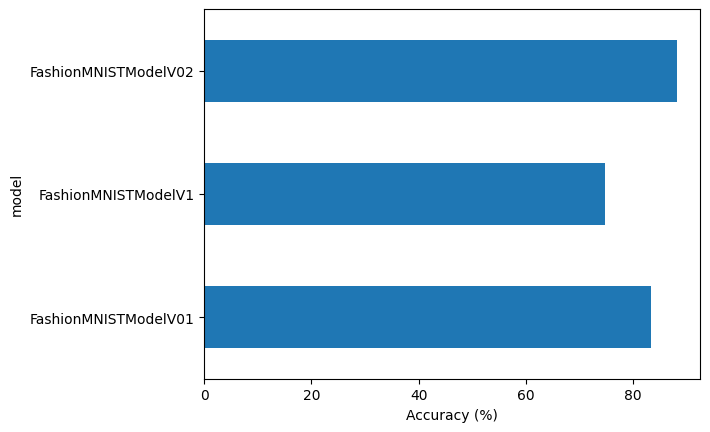

In [ ]:
compare_results.set_index("model_name")["model_acc"].plot(kind="barh")
plt.xlabel("Accuracy (%)")
plt.ylabel("model")

In [ ]:
def make_prediction(model: torch.nn.Module, data: list, device: torch.device = device):
  pred_probs = []
  model.eval()
  with torch.inference_mode():
    for sample in data:
      sample = torch.unsqueeze(sample, dim=0).to(device)
      pred_logit = model(sample)
      pred_prob = torch.softmax(pred_logit.squeeze(), dim=0)
      pred_probs.append(pred_prob)
  return torch.stack(pred_probs)

Text(0.5, 1.0, 'Sneaker')

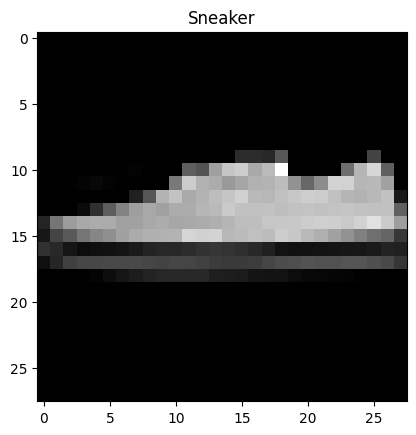

In [ ]:
import random
random_seed = 42
test_samples = []
test_labels = []

for samples, labels in random.sample(list(test_data), k=9):
  test_samples.append(samples)
  test_labels.append(labels)

test_samples[0].shape
plt.imshow(test_samples[0].squeeze(), cmap="gray")
plt.title(class_names[test_labels[0]])



In [ ]:
pred_probs = make_prediction(model_02, test_samples)
pred_labels =[]
for pred_prob in pred_probs:
  pred_labels.append(pred_prob.argmax(dim=0))
pred_labels = torch.stack(pred_labels, dim=0)
print(f"{torch.tensor(test_labels)} \n{pred_labels}")

tensor([7, 8, 6, 1, 7, 5, 5, 7, 8]) 
tensor([7, 8, 4, 1, 7, 5, 5, 7, 8])


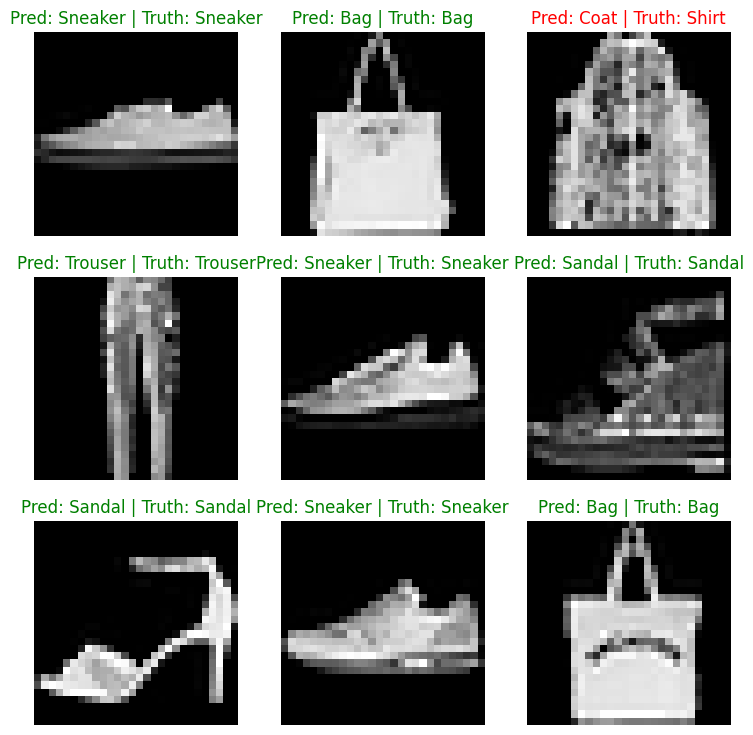

In [ ]:
plt.figure(figsize=(9,9))
nrows = 3
ncols = 3
for i, sample in enumerate(test_samples):
  plt.subplot(nrows, ncols, i+1)
  plt.imshow(sample.squeeze(), cmap = "gray")
  # find the prediction in text form e.g "Sandal"
  pred_label = class_names[pred_labels[i]]
  # find the truth label in text form
  truth_label = class_names[test_labels[i]]
  c = "g" if pred_label == truth_label else "r"
  plt.title(f"Pred: {pred_label} | Truth: {truth_label}" , c=c)
  plt.axis(False)



In [ ]:
y_preds = []
model_02.eval()
with torch.inference_mode():
  for X, y in tqdm(test_dataloader, desc="Making predictions..."):
    X, y = X.to(device), y.to(device)
    y_logits = model_02(X)
    y_pred = torch.softmax(y_logits, dim=0).argmax(dim=1)
    y_preds.append(y_pred.cpu())


# print(y_preds)
y_pred_tensor = torch.cat(y_preds)
y_pred_tensor


Making predictions...:   0%|          | 0/313 [00:00<?, ?it/s]

tensor([9, 2, 1,  ..., 8, 1, 8])

In [ ]:
import mlxtend
mlxtend.__version__

'0.23.4'

In [ ]:
!pip install torchmetrics


In [ ]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

# Configure ConfusionMatrix with the mandatory 'task' argument
confmat = ConfusionMatrix(task="multiclass", num_classes=len(class_names))
confmat_tensor = confmat(preds=y_pred_tensor, target=test_data.targets)
confmat_tensor

tensor([[628,   5,  44,  79,  12,   1, 224,   0,   7,   0],
        [  8, 895,   7,  68,  13,   0,   5,   0,   3,   1],
        [  7,   1, 810,  13,  95,   0,  69,   0,   5,   0],
        [ 25,  13,  25, 861,  36,   0,  34,   0,   4,   2],
        [  5,   6, 117,  50, 712,   0, 106,   0,   4,   0],
        [  6,   0,   9,  11,   0, 840,   4,  44,  66,  20],
        [ 69,   7, 123,  64,  98,   0, 626,   0,  13,   0],
        [  1,   1,   0,   1,   0,  33,   0, 877,  18,  69],
        [  8,   2,  23,  17,   6,   7,  29,   7, 900,   1],
        [  1,   0,   1,   2,   0,  20,   4,  71,  11, 890]])

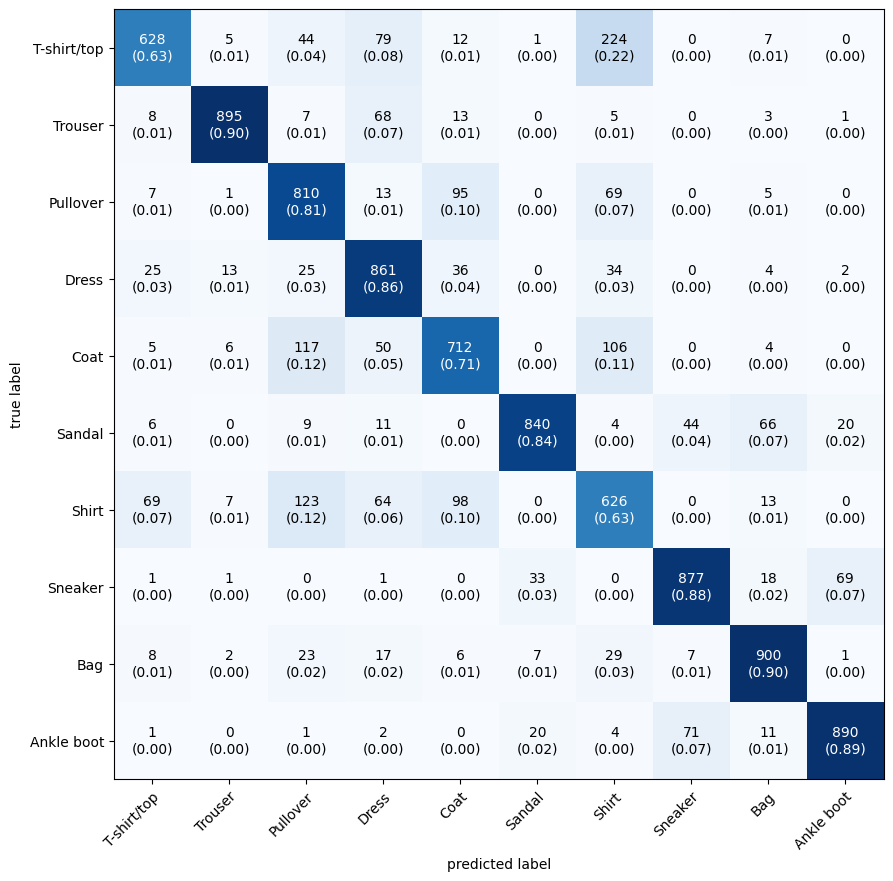

In [ ]:
# plotting confusion matrix
fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),
    figsize=(10, 10),
    class_names=class_names,
    show_normed=True
)

save and load best performing model


In [ ]:
from pathlib import Path

# creating model path
MODEL_PATH = Path("model")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "fashion_mnist_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# save the model state dict
print(f"saving to {MODEL_SAVE_PATH}.....")
torch.save(obj=model_02.state_dict(), f=MODEL_SAVE_PATH)
print("model saved")

saving to model/fashion_mnist_model.pth
model saved


loading the model

In [ ]:
loaded_model = FashionMNISTModelV02(input_shape=1,
                                    hidden_units=10,
                                    output_shape=len(class_names)).to(device)
loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH))
loaded_model.to(device)
loaded_model

FashionMNISTModelV02(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [ ]:
torch.manual_seed(42)
loaded_model_result = eval_model(
    model=loaded_model,
    data_loader=test_dataloader,
    loss_fn=loss_fn,
    accuracy_fn=accuracy_fn
)
loaded_model_result

{'model_name': 'FashionMNISTModelV02',
 'model_loss': 0.32718968391418457,
 'model_acc': 88.06908945686901}

In [ ]:
model_02_results

{'model_name': 'FashionMNISTModelV02',
 'model_loss': 0.32718968391418457,
 'model_acc': 88.06908945686901}

In [ ]:
# check if loaded model performance is close to the original model

torch.isclose(torch.tensor(model_02_results["model_acc"]), torch.tensor(loaded_model_result["model_acc"]), atol=0.02)

tensor(True)